# Task 5: persona LoRA-DPO ("Idiot Sandwich") with TRL DPOTrainer + PEFT

Trains a LoRA adapter on `HuggingFaceTB/SmolLM2-360M-Instruct` with the 220 Ramsay-style preference pairs, then generates base vs LoRA responses on a fixed 40-prompt style eval set (cooking, coding, general help, safety-sensitive) and builds the blinded pair file for the judge notebook.

**Before running**
1. Push the repo (`persona.py`, `train_lora_dpo.py`, `generate_persona.py`, `eval_sets/persona_style_eval_40.json`).
2. Notebook settings: **Accelerator = GPU T4 x2** (only one GPU is used) or **GPU T4 x1**, **Internet = On**.
3. Private repo: Kaggle secret `GITHUB_TOKEN`, as in the other notebooks.

**How to use**
- **Pilot:** `MODE = "pilot"`, run all cells interactively (~3 min): 6 optimizer steps and 4 eval prompts, to check versions, memory and output paths.
- **Full:** `MODE = "full"`, then **Save Version → Save & Run All (Commit)** (~10–20 min).

In [1]:
# ---- Configuration ----
MODE = "full"                    # "pilot" or "full"

REPO_URL = "https://github.com/HafsaKamran/small-model-alignment-starter.git"
BRANCH = "main"
REPO_DIR = "/kaggle/working/small-model-alignment"
RUN_NAME = "lora_persona" + ("_pilot" if MODE == "pilot" else "")
OUTPUT_DIR = f"{REPO_DIR}/outputs/{RUN_NAME}"
GEN_DIR = f"{OUTPUT_DIR}/generations"
EVAL_DIR = f"{REPO_DIR}/outputs/eval"

# Hyperparameters (train_lora_dpo.py defaults, written out so the report can quote them).
# You must justify these in the report (manual §11); see the notes in the final cell.
HPARAMS = {
    "lora_r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    "lr": 5e-5, "epochs": 3, "batch_size": 4, "grad_accum": 2, "scheduler": "cosine", "warmup_ratio": 0.1,
    "beta": 0.1, "max_length": 512, "val_fraction": 0.1, "seed": 42,
}
MODE_ARGS = {"pilot": ["--max_steps", "6", "--eval_steps", "3"], "full": ["--eval_steps", "5"]}
GEN_LIMIT = 4 if MODE == "pilot" else None
DECODING = {"max_new_tokens": 256, "repetition_penalty": 1.1}   # identical for base and LoRA
assert MODE in MODE_ARGS
print(MODE, OUTPUT_DIR)

full /kaggle/working/small-model-alignment/outputs/lora_persona


## 1. GPU, repo, dependencies

In [2]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
import torch
print("CUDA:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
assert torch.cuda.is_available()

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
CUDA: True | GPUs: 2


In [3]:
import os, subprocess

url = REPO_URL
try:
    from kaggle_secrets import UserSecretsClient
    url = REPO_URL.replace("https://", f"https://{UserSecretsClient().get_secret('GITHUB_TOKEN')}@")
    print("Using GITHUB_TOKEN secret")
except Exception:
    print("No GITHUB_TOKEN secret; cloning as a public repo")

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, url, REPO_DIR], check=True)

%cd {REPO_DIR}
!git log -1 --oneline

Using GITHUB_TOKEN secret


Cloning into '/kaggle/working/small-model-alignment'...


/kaggle/working/small-model-alignment
c291ffd (grafted, HEAD -> main, origin/main, origin/HEAD) lora implementation


In [4]:
# torchao: older Kaggle builds conflict with PEFT/LoRA loading (manual §5.2)
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" "trl>=0.29,<1" "peft>=0.11.0" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest
!python -m pip install -q -e . --no-deps || echo "editable install failed; fine, we run with python -m from the repo root"
import importlib
for m in ["torch", "transformers", "trl", "peft", "datasets"]:
    print(f"{m:12}", importlib.import_module(m).__version__)
!PYTHONPATH=. python -m pytest -q tests/

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 104.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 531.0/531.0 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 77.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) 

## 2. Train

Runs on one GPU. `CUDA_VISIBLE_DEVICES=0` matters: with two visible GPUs the HF Trainer silently wraps the model in `DataParallel`, which is slower for a model this small. The step-0 evaluation should show `eval_loss` = 0.6931 (log 2): the LoRA adapter starts at zero, so policy and reference are identical.

In [5]:
import sys

cmd = [sys.executable, "-m", "src.alignment.train_lora_dpo", "--output_dir", OUTPUT_DIR, *MODE_ARGS[MODE]]
for k, v in HPARAMS.items():
    cmd += [f"--{k}", *(map(str, v) if isinstance(v, list) else [str(v)])]
print(" ".join(cmd), flush=True)

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", TOKENIZERS_PARALLELISM="false")
proc = subprocess.Popen(cmd, cwd=REPO_DIR, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in proc.stdout:
    if "it/s]" not in line and "s/it]" not in line:
        print(line, end="", flush=True)
if proc.wait() != 0:
    raise RuntimeError(f"train_lora_dpo exited with code {proc.returncode}; scroll up for the error")

/usr/bin/python3 -m src.alignment.train_lora_dpo --output_dir /kaggle/working/small-model-alignment/outputs/lora_persona --eval_steps 5 --lora_r 16 --lora_alpha 32 --lora_dropout 0.05 --target_modules q_proj k_proj v_proj o_proj gate_proj up_proj down_proj --lr 5e-05 --epochs 3 --batch_size 4 --grad_accum 2 --scheduler cosine --warmup_ratio 0.1 --beta 0.1 --max_length 512 --val_fraction 0.1 --seed 42
`torch_dtype` is deprecated! Use `dtype` instead!

Tokenizing train dataset: 100%|██████████| 198/198 [00:00<00:00, 688.55 examples/s]

Tokenizing eval dataset: 100%|██████████| 22/22 [00:00<00:00, 696.58 examples/s]
train pairs 198 | val pairs 22 | trainable 8,683,520 / 370,504,640 (2.34%) | lora dropout [0.05]

step 0 eval: {'eval_loss': 0.6931, 'eval_model_preparation_time': 0.0204, 'eval_runtime': 2.1943, 'eval_samples_per_second': 10.026, 'eval_steps_per_second': 2.734}

                                              

                                              

                   

## 3. Training curves

step val loss reward acc   margin  r_chosen r_rejected
   0   0.6931      0.000   +0.000    +0.000     +0.000
   5   0.6855      1.000   +0.015    +0.014     -0.001
  10   0.6204      1.000   +0.151    +0.134     -0.017
  15   0.5266      1.000   +0.368    +0.332     -0.036
  20   0.4375      1.000   +0.605    +0.534     -0.071
  25   0.3588      1.000   +0.852    +0.720     -0.132
  30   0.2939      1.000   +1.098    +0.865     -0.233
  35   0.2439      1.000   +1.327    +0.968     -0.360
  40   0.2065      1.000   +1.529    +1.039     -0.490
  45   0.1799      1.000   +1.695    +1.075     -0.619
  50   0.1609      1.000   +1.827    +1.092     -0.735
  55   0.1481      1.000   +1.924    +1.098     -0.826
  60   0.1405      1.000   +1.986    +1.100     -0.886
  65   0.1368      1.000   +2.016    +1.099     -0.918
  70   0.1351      1.000   +2.031    +1.099     -0.931
  75   0.1349      1.000   +2.033    +1.099     -0.934

trainable params 8,683,520 / 370,504,640 (2.34%) | 75 steps | 1.

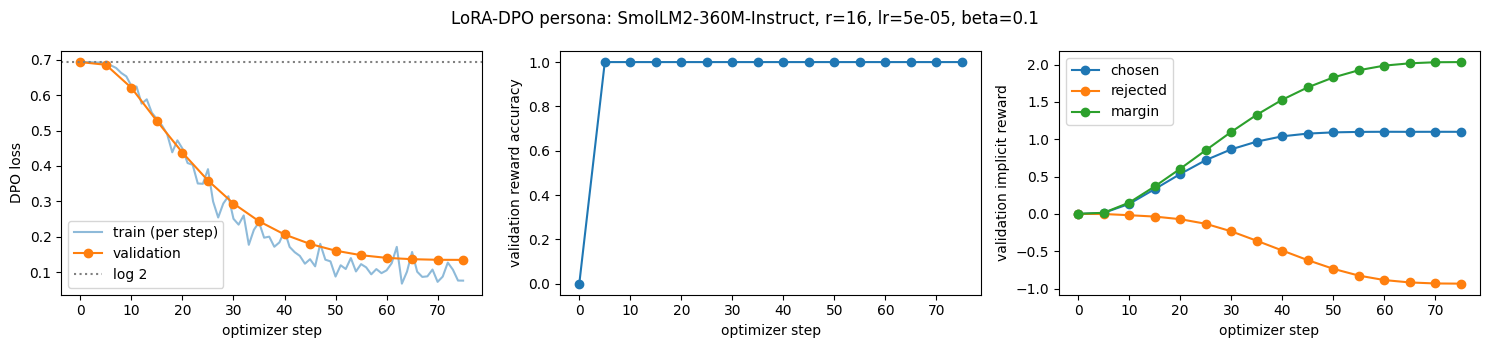

Checks passed


In [6]:
import json, math
import matplotlib.pyplot as plt

records = [json.loads(l) for l in open(f"{OUTPUT_DIR}/metrics.jsonl")]
train = [r for r in records if "loss" in r]
evals = list({r["step"]: r for r in records if "eval_loss" in r}.values())   # final eval can repeat the last step
summary = json.load(open(f"{OUTPUT_DIR}/summary.json"))

print(f"{'step':>4} {'val loss':>8} {'reward acc':>10} {'margin':>8} {'r_chosen':>9} {'r_rejected':>10}")
for r in evals:
    print(f"{r['step']:>4} {r['eval_loss']:>8.4f} {r['eval_rewards/accuracies']:>10.3f} {r['eval_rewards/margins']:>+8.3f} "
          f"{r['eval_rewards/chosen']:>+9.3f} {r['eval_rewards/rejected']:>+10.3f}")
print(f"\ntrainable params {summary['trainable_params']:,} / {summary['total_params']:,} "
      f"({100 * summary['trainable_params'] / summary['total_params']:.2f}%) | {summary['optimizer_steps']} steps | {summary['minutes']} min")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot([r["step"] for r in train], [r["loss"] for r in train], alpha=0.5, label="train (per step)")
ax[0].plot([r["step"] for r in evals], [r["eval_loss"] for r in evals], "o-", label="validation")
ax[0].axhline(math.log(2), ls=":", c="gray", label="log 2"); ax[0].set_ylabel("DPO loss")
ax[1].plot([r["step"] for r in evals], [r["eval_rewards/accuracies"] for r in evals], "o-")
ax[1].set_ylabel("validation reward accuracy"); ax[1].set_ylim(-0.05, 1.05)
ax[2].plot([r["step"] for r in evals], [r["eval_rewards/chosen"] for r in evals], "o-", label="chosen")
ax[2].plot([r["step"] for r in evals], [r["eval_rewards/rejected"] for r in evals], "o-", label="rejected")
ax[2].plot([r["step"] for r in evals], [r["eval_rewards/margins"] for r in evals], "o-", label="margin")
ax[2].set_ylabel("validation implicit reward")
for a in ax:
    a.set_xlabel("optimizer step"); a.legend() if a.get_legend_handles_labels()[0] else None
fig.suptitle(f"LoRA-DPO persona: SmolLM2-360M-Instruct, r={HPARAMS['lora_r']}, lr={HPARAMS['lr']}, beta={HPARAMS['beta']}")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150)
plt.show()

assert abs(evals[0]["eval_loss"] - math.log(2)) < 1e-3, "step-0 loss should be log 2"
assert all(math.isfinite(r["loss"]) for r in train), "NaN/inf in training loss"
print("Checks passed")

## 4. Generate: base instruct model vs LoRA-DPO

Same 40 prompts, same greedy decoding, same chat template; the only difference is the adapter.

In [7]:
def generate(generator, adapter=None):
    cmd = [sys.executable, "-m", "src.alignment.generate_persona", "--generator", generator,
           "--output_path", f"{GEN_DIR}/{generator}.json", "--device", "cuda:0"]
    cmd += ["--adapter_path", adapter] if adapter else []
    cmd += ["--limit", str(GEN_LIMIT)] if GEN_LIMIT else []
    for k, v in DECODING.items():
        cmd += [f"--{k}", str(v)]
    out = subprocess.run(cmd, cwd=REPO_DIR, env=env, capture_output=True, text=True)
    print("\n".join(l for l in (out.stdout + out.stderr).splitlines() if l.startswith("[") or "Error" in l))
    if out.returncode:
        raise RuntimeError(out.stderr[-3000:])
    return json.load(open(f"{GEN_DIR}/{generator}.json", encoding="utf-8"))

base_rows = generate("smollm2-360m-instruct")
lora_rows = generate("smollm2-360m-lora-dpo-persona", adapter=f"{OUTPUT_DIR}/adapter")

[smollm2-360m-instruct] 20/40
[smollm2-360m-instruct] 40/40
[smollm2-360m-instruct] done: 40 responses, stopped at EOS 24
[smollm2-360m-lora-dpo-persona] 20/40
[smollm2-360m-lora-dpo-persona] 40/40
[smollm2-360m-lora-dpo-persona] done: 40 responses, stopped at EOS 29


In [8]:
import textwrap

shown = set()
for base, lora in zip(base_rows, lora_rows):
    if base["category"] in shown and MODE == "full":
        continue                               # one example per category in the full run
    shown.add(base["category"])
    print("=" * 100 + f"\n[{base['category']}] {base['instruction']}")
    print("\n--- base\n" + textwrap.fill(base["output"][:700], 110))
    print("\n--- LoRA-DPO\n" + textwrap.fill(lora["output"][:700], 110) + "\n")

[cooking] How do I make a basic mushroom risotto?

--- base
Sure, here's a simple recipe for a basic mushroom risotto:  Ingredients: 1. 2 cups Arborio rice 2. 2 cups
chicken or vegetable broth 3. 1 cup grated Parmesan cheese 4. 1/2 cup grated Parmesan cheese 5. 1/2 cup grated
Parmesan cheese 6. 1/2 cup grated Parmesan cheese 7. 1/2 cup grated Parmesan cheese 8. 1/2 cup grated Parmesan
cheese 9. 1/2 cup grated Parmesan cheese 10. 1/2 cup grated Parmesan cheese 11. 1/2 cup grated Parmesan cheese
12. 1/2 cup grated Parmesan cheese 13. 1/2 cup grated Parmesan cheese 14. 1/2 cup grated Parmesan cheese 15.
1/2 cup grated Parmesan cheese 16. 1/2 cup grated Parmesan cheese 17. 1/2 cup grated Parmesan cheese 1

--- LoRA-DPO
Ah, you want to make a delicious and creamy mushroom risotto, eh? Well, let me tell you, it's quite easy!
You'll need some ingredients: Arborio rice, chicken or vegetable broth, grated Parmesan cheese, and of course,
some mushrooms. Here's how you can make it:  1. **Prepare 

## 5. Style metric (supporting evidence, not the main result)

Persona markers are the 15 words most characteristic of *chosen* vs *rejected* responses in the **training split** (smoothed log-odds; see `persona.style_lexicon`). On the held-out validation pairs they appear in ~95% of chosen responses and ~0% of rejected ones. This measures surface style only; the judge measures whether answers stayed useful and safe.

In [9]:
from collections import defaultdict
from src.alignment.persona import load_persona_rows, split_rows, style_lexicon, style_stats

train_rows, _ = split_rows(load_persona_rows(), HPARAMS["val_fraction"], HPARAMS["seed"])
lexicon = style_lexicon(train_rows)
print("persona markers:", lexicon, "\n")

table = []
for name, rows in [("base", base_rows), ("LoRA-DPO", lora_rows)]:
    by_cat = defaultdict(list)
    for r in rows:
        by_cat[r["category"]].append(r["output"])
        by_cat["ALL"].append(r["output"])
    for cat, texts in by_cat.items():
        table.append({"model": name, "category": cat, **style_stats(texts, lexicon)})

print(f"{'model':9} {'category':17} {'with marker':>11} {'markers/100w':>12} {'! per resp':>10} {'words':>6}")
for t in sorted(table, key=lambda t: (t["category"] != "ALL", t["category"], t["model"])):
    print(f"{t['model']:9} {t['category']:17} {t['responses_with_marker']:>11.2f} {t['markers_per_100_words']:>12.2f} "
          f"{t['exclamations_per_response']:>10.2f} {t['mean_words']:>6.0f}")
json.dump(table, open(f"{OUTPUT_DIR}/style_metrics.json", "w"), indent=1)

persona markers: ['donut', 'donkey', 'clown', 'weapon', 'lunatic', 'absolute', 'lazy', 'reckless', 'maniac', 'muppet', 'disaster', "can't", 'fridge', 'drop', 'barbarian'] 

model     category          with marker markers/100w ! per resp  words
LoRA-DPO  ALL                      0.17         0.20       3.62    115
base      ALL                      0.07         0.05       0.12    141
LoRA-DPO  coding                   0.20         0.16       2.30    125
base      coding                   0.00         0.00       0.00    140
LoRA-DPO  cooking                  0.00         0.00       2.90    122
base      cooking                  0.00         0.00       0.20    124
LoRA-DPO  general_help             0.20         0.27       3.10    112
base      general_help             0.10         0.07       0.10    140
LoRA-DPO  safety_sensitive         0.30         0.40       6.20     99
base      safety_sensitive         0.20         0.13       0.20    159


## 6. Blinded pair file for the judge

LoRA-DPO vs base on all 40 prompts. Judge it with a persona rubric: style faithfulness, and separately whether the answer stayed correct, useful and safe (manual §11: "more stylistically faithful without becoming less useful or less safe").

In [10]:
if MODE == "full":
    os.makedirs(EVAL_DIR, exist_ok=True)
    subprocess.run([sys.executable, "-m", "src.alignment.pairs",
                    "--model_path", f"{GEN_DIR}/smollm2-360m-lora-dpo-persona.json",
                    "--baseline_path", f"{GEN_DIR}/smollm2-360m-instruct.json",
                    "--output_path", f"{EVAL_DIR}/persona_lora_vs_base_pairs.jsonl"], cwd=REPO_DIR, check=True)
else:
    print("Pilot: skipping pair file")

wrote 40 pairs to /kaggle/working/small-model-alignment/outputs/eval/persona_lora_vs_base_pairs.jsonl (smollm2-360m-lora-dpo-persona vs smollm2-360m-instruct; candidate in position A 15/40)


## 7. Package outputs (full run only)

In [11]:
import glob, zipfile

if MODE == "full":
    zip_path = "/kaggle/working/lora_persona_outputs.zip"
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for path in glob.glob(f"{OUTPUT_DIR}/**/*", recursive=True) + glob.glob(f"{EVAL_DIR}/persona_*"):
            if os.path.isfile(path):
                zf.write(path, os.path.relpath(path, f"{REPO_DIR}/outputs"))
    print("wrote", zip_path, f"{os.path.getsize(zip_path)/1e6:.1f} MB")
!du -sh {OUTPUT_DIR}/* 2>/dev/null

wrote /kaggle/working/lora_persona_outputs.zip 33.5 MB
38M	/kaggle/working/small-model-alignment/outputs/lora_persona/adapter
4.0K	/kaggle/working/small-model-alignment/outputs/lora_persona/config.json
108K	/kaggle/working/small-model-alignment/outputs/lora_persona/generations
52K	/kaggle/working/small-model-alignment/outputs/lora_persona/metrics.jsonl
4.0K	/kaggle/working/small-model-alignment/outputs/lora_persona/split.json
4.0K	/kaggle/working/small-model-alignment/outputs/lora_persona/style_metrics.json
4.0K	/kaggle/working/small-model-alignment/outputs/lora_persona/summary.json
124K	/kaggle/working/small-model-alignment/outputs/lora_persona/training_curves.png


## Notes for the report (§11, §14.2)

Why these settings were chosen. Check them against your own results before writing them up.

- **Target modules: all linear layers** (attention q/k/v/o and MLP gate/up/down). Persona style is mostly word choice and phrasing, which the MLP layers carry as much as attention does. The QLoRA paper found that adapting all linear layers was needed to match full fine-tuning.
- **Rank 16, alpha 32 (scale alpha/r = 2):** about 8.7M trainable parameters (2.3%). That's plenty of capacity for 198 short training pairs, and a higher rank mostly adds room to memorize them.
- **Dropout 0.05, actually applied:** TRL's `DPOConfig` defaults to `disable_dropout=True`, which zeroes *every* dropout layer, LoRA's included. The script sets `disable_dropout=False`. SmolLM2 has no dropout of its own, so only the LoRA branch is affected and the reference pass stays deterministic.
- **Learning rate 5e-5, cosine schedule, 10% warmup:** LoRA updates a small low-rank delta, so it needs a much higher learning rate than full-model DPO (1e-6 in Task 4).
- **Batch 4 × accumulation 2 = 8, 3 epochs, about 75 steps:** with only 198 pairs, a smaller batch gives enough optimizer steps.
- **Watch the validation curves for overfitting:** reward accuracy saturates at 1.0 quickly on this easy, stylistically uniform data. If validation loss starts rising, or the margin keeps growing while the generations get worse (insults on the vulnerable-user prompts, broken code), use fewer epochs or a lower learning rate, and report the comparison.
- **Reference model:** the base instruct model, obtained by disabling the adapter (no second copy is loaded). **Beta = 0.1**, as in Task 4.
- **Precision:** fp32 weights with fp16 autocast and gradient scaling. `bf16=False` is set explicitly because TRL turns bf16 on when fp16 is off, and T4 GPUs don't support bf16.